In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Dataset Load karein
df = pd.read_csv('KC_House_Data.csv')

# Unnecessary string column ('date') drop karein
if 'date' in df.columns:
    df_clean = df.drop(columns=['date'])
else:
    df_clean = df.copy()

# Data preview check karein
df_clean.head()

,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7700000,6,8.00,12050,27600,2.5,0,3,4,13,8570,3480,1910,1987,98102,47.6298,-122.323,3940,8800
1,7062500,5,4.50,10040,37325,2.0,1,2,3,11,7680,2360,1940,2001,98004,47.6500,-122.214,3930,25449
2,6885000,6,7.75,9890,31374,2.0,0,4,3,13,8860,1030,2001,0,98039,47.6305,-122.240,4540,42730
3,5570000,5,5.75,9200,35069,2.0,0,0,3,13,6200,3000,2001,0,98039,47.6289,-122.233,3560,24345
4,5350000,5,5.00,8000,23985,2.0,0,4,3,12,6720,1280,2009,0,98004,47.6232,-122.220,4600,21750


In [2]:
# Dependent Variable (Target)
y = df_clean['price']

# Independent Variables (Features)
X = df_clean.drop(columns=['price'])

print("X shape (Features):", X.shape)
print("y shape (Target):", y.shape)

X shape (Features): (21613, 18)
y shape (Target): (21613,)


In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 17290
Testing samples: 4323


In [4]:
# Do columns ke beech correlation calculate karein
correlation_value = df['sqft_living'].corr(df['price'])

print(f"sqft_living aur price ke beech correlation: {correlation_value:.4f}")

sqft_living aur price ke beech correlation: 0.7020


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model Training Complete!")

Model Training Complete!


In [6]:
# Predictions
y_pred = model.predict(X_test)

# Error Metrics Calculation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Results Display
print("=== Multivariate Error Metrics ===")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R²) Score: {r2:.4f}")

=== Multivariate Error Metrics ===
Mean Absolute Error (MAE): 122890.0662
Mean Squared Error (MSE): 36644457856.1528
Root Mean Squared Error (RMSE): 191427.4219
R-squared (R²) Score: 0.6969


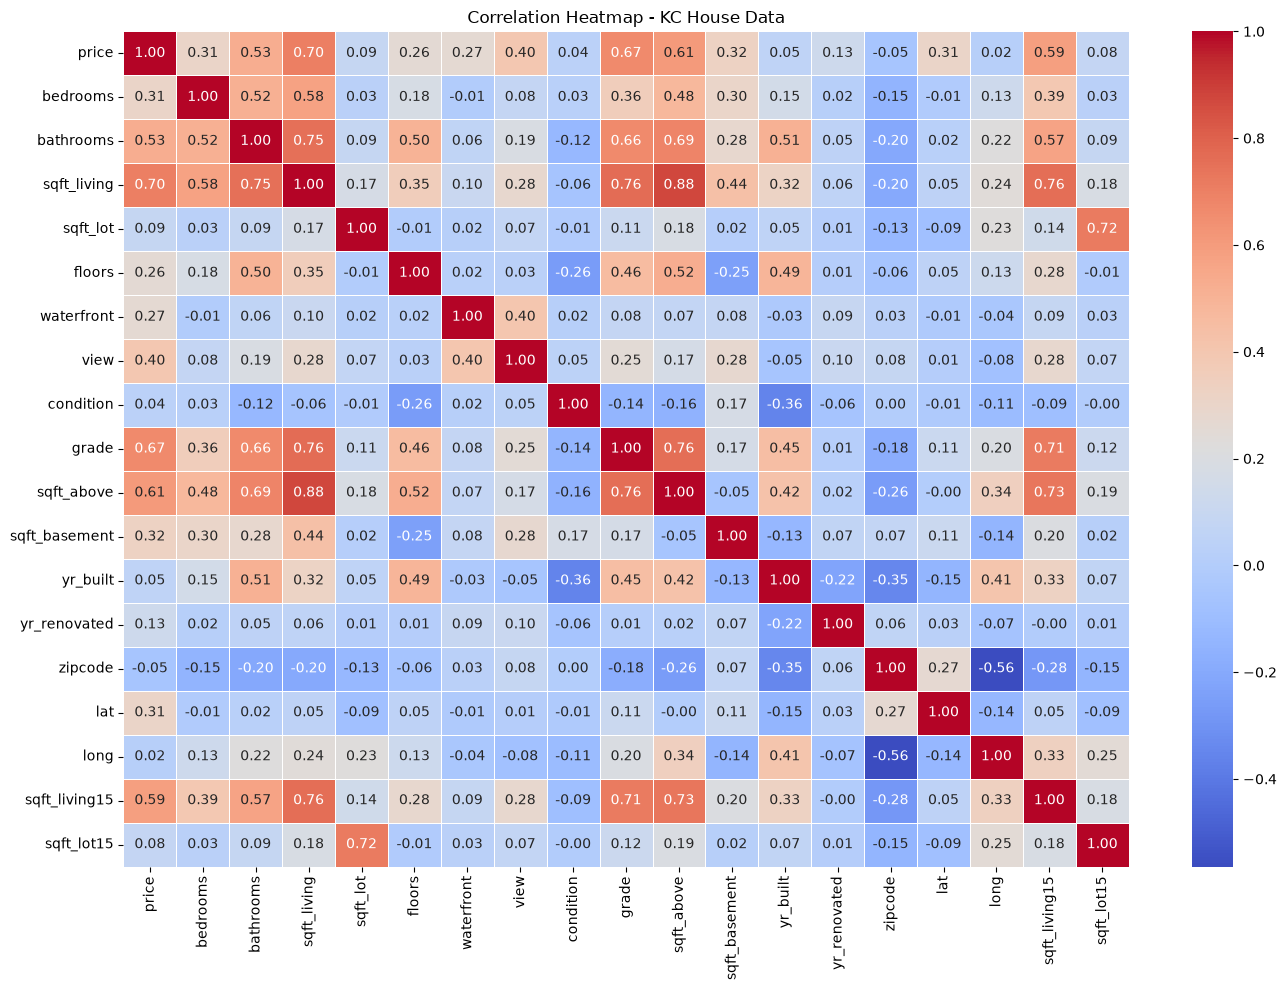

In [8]:
# plt.figure(figsize=(14, 10))

# correlation_matrix = df.select_dtypes(include=np.number).corr()

# sns.heatmap(
#     correlation_matrix,
#     annot=True,
#     fmt=".2f",
#     cmap="coolwarm"
# )

# plt.title("Correlation Heatmap")
# plt.show()


plt.figure(figsize=(14, 10))
sns.heatmap(df_clean.corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap - KC House Data')
plt.tight_layout()
plt.show()